# Proyecto integrador Big Data 2026-2 — US Accidents (2016–2023)
## Entrega de avance: ingesta, calidad, limpieza y procesamiento inicial con PySpark

**Universidad Santo Tomás, Seccional Tunja** · Facultad de Ingeniería de Sistemas · Big Data 2026-2  
**Docente:** Marta Susana Contreras Ortiz  
**Integrantes:** Diego Esteban Buitrago, Camilo Hernández y Juan Esteban Tovar  
**Fecha:** 5 de noviembre de 2026

**Contenido:** Parte 1 — entorno, ingesta a la capa bronce y diagnóstico de calidad. Parte 2 — limpieza hacia la capa plata, métricas antes/después, diccionario de datos, procesamiento con PySpark y Spark SQL, y capa oro inicial para el dashboard.

**Temáticas aplicadas:** Obligatoria 1 (PySpark: filtros, `groupBy`, join, Spark SQL, verificación con `count()`), Obligatoria 2 (limpieza y transformación documentadas) y Electiva B (capas bronce → plata → oro, diccionario de datos y responsables).

### Preguntas de análisis

1. ¿Cómo evolucionó el número de accidentes reportados entre 2016 y 2022, y qué estados y regiones concentran la mayor cantidad?
2. ¿En qué horas del día y días de la semana se concentran los accidentes, y en qué franjas es mayor la proporción de accidentes graves (severidad 3–4)?
3. ¿Qué condiciones climáticas (tipo de clima, visibilidad, precipitación) se asocian con una mayor proporción de accidentes graves?
4. ¿Qué elementos de infraestructura vial (semáforo, cruce, intersección, pare) se asocian con una mayor o menor proporción de accidentes graves?
5. ¿Cuánto dura el impacto en el tráfico según la severidad del accidente y la región del país?

*2023 solo tiene datos de enero a marzo, así que se excluye de las tendencias anuales.*

## 1. Configuración del entorno

In [ ]:
# Montar Google Drive: aquí vive el data lake del proyecto (Colab borra /content al desconectarse)
from google.colab import drive
drive.mount('/content/drive')

import os, re, sys, glob, json, shutil, hashlib, subprocess, datetime as dt

BASE       = '/content/drive/MyDrive/us-accidents-bigdata'
DATA       = f'{BASE}/data'
BRONZE_RAW = f'{DATA}/bronze/raw'       # fuente original tal como llegó (.zip)
BRONZE_PQ  = f'{DATA}/bronze/parquet'   # misma información en Parquet, sin limpiar
SILVER     = f'{DATA}/silver'           # datos limpios y tipados (parte 2)
GOLD       = f'{DATA}/gold'             # agregados para el dashboard (parte 2)
REFERENCE  = f'{DATA}/reference'        # tablas de referencia (estados, regiones)
DOCS       = f'{BASE}/docs'             # tablas y figuras para el documento
TMP        = '/content/tmp'             # disco local rápido de Colab (temporal)

for d in [BRONZE_RAW, SILVER, GOLD, REFERENCE, DOCS, f'{BASE}/notebooks', f'{BASE}/app', TMP]:
    os.makedirs(d, exist_ok=True)

print('Carpetas del proyecto en Drive:')
for d in sorted(glob.glob(f'{BASE}/**/', recursive=True))[:20]:
    print(' ', d.replace(BASE, 'us-accidents-bigdata'))

Mounted at /content/drive
Carpetas del proyecto en Drive:
  us-accidents-bigdata/
  us-accidents-bigdata/app/
  us-accidents-bigdata/data/
  us-accidents-bigdata/data/bronze/
  us-accidents-bigdata/data/bronze/parquet/
  us-accidents-bigdata/data/bronze/raw/
  us-accidents-bigdata/data/gold/
  us-accidents-bigdata/data/gold/accidentes_anio_mes_estado/
  us-accidents-bigdata/data/gold/accidentes_clima/
  us-accidents-bigdata/data/gold/accidentes_hora_dia/
  us-accidents-bigdata/data/gold/accidentes_infraestructura/
  us-accidents-bigdata/data/reference/
  us-accidents-bigdata/data/silver/
  us-accidents-bigdata/data/silver/accidentes/
  us-accidents-bigdata/data/silver/accidentes/year=2016/
  us-accidents-bigdata/data/silver/accidentes/year=2017/
  us-accidents-bigdata/data/silver/accidentes/year=2018/
  us-accidents-bigdata/data/silver/accidentes/year=2019/
  us-accidents-bigdata/data/silver/accidentes/year=2020/
  us-accidents-bigdata/data/silver/accidentes/year=2021/


In [ ]:
# Verificar Java (requisito de Spark) e instalar PySpark solo si no está
r = subprocess.run(['java', '-version'], capture_output=True, text=True)
if r.returncode != 0:
    subprocess.run('apt-get -qq install -y openjdk-17-jdk-headless', shell=True, check=True)
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-17-openjdk-amd64'
    r = subprocess.run(['java', '-version'], capture_output=True, text=True)
print((r.stderr or r.stdout).splitlines()[0])

try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyspark==3.5.3'], check=True)
    import pyspark
print('PySpark', pyspark.__version__)

openjdk version "21.0.12.1" 2026-08-18
PySpark 4.0.5


In [ ]:
from pyspark.sql import SparkSession, functions as F, types as T
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

spark = (SparkSession.builder
         .appName('US_Accidents_BigData')
         .master('local[*]')
         .config('spark.driver.memory', '8g')            # Colab gratuito tiene ~12 GB de RAM
         .config('spark.sql.shuffle.partitions', '16')   # una sola máquina: pocas particiones de shuffle
         .config('spark.sql.session.timeZone', 'UTC')
         .config('spark.sql.ansi.enabled', 'false')      # un cast inválido devuelve null (lo usamos para medir tipos incorrectos)
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 200)
print('Spark', spark.version, '| núcleos:', spark.sparkContext.defaultParallelism)

Spark 4.0.5 | núcleos: 2


## 2. Ingesta a la capa bronce

**Fuente:** Moosavi, S. *US Accidents (2016–2023)*, Kaggle (`sobhanmoosavi/us-accidents`). Licencia CC BY-NC-SA 4.0 (verificar en la página del dataset).

Flujo de la celda siguiente:

1. Si la capa bronce ya existe en Drive, no se descarga nada (salvo que `REPROCESAR = True`).
2. Si el `.zip` ya está en `bronze/raw/` de Drive, se copia a disco local; si no, se descarga con la API de Kaggle y se respalda en Drive.
3. Se descomprime en `/content/tmp` (disco local de Colab, más rápido que Drive para leer 3 GB).

In [ ]:
REPROCESAR = False                 # True para repetir la ingesta desde el archivo original
ZIP_NAME   = 'us-accidents.zip'
zip_drive  = f'{BRONZE_RAW}/{ZIP_NAME}'
zip_tmp    = f'{TMP}/{ZIP_NAME}'
META_PATH  = f'{DOCS}/ingesta_metadata.json'

def tam_mb(path):
    # Tamaño de un archivo o carpeta en MB
    if os.path.isfile(path):
        return os.path.getsize(path) / 1024**2
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1024**2

def sha256(path, bloque=1 << 24):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(bloque), b''):
            h.update(b)
    return h.hexdigest()

HACER_INGESTA = REPROCESAR or not os.path.exists(f'{BRONZE_PQ}/_SUCCESS')

if not HACER_INGESTA:
    print('La capa bronce ya existe en Drive; se reutiliza (REPROCESAR = False).')
else:
    if os.path.exists(zip_drive):
        print('Zip encontrado en Drive; copiando a disco local...')
        shutil.copy(zip_drive, zip_tmp)
    else:
        from google.colab import userdata
        os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY']      = userdata.get('KAGGLE_KEY')
        if shutil.which('kaggle') is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'], check=True)
        print('Descargando desde Kaggle...')
        subprocess.run(['kaggle', 'datasets', 'download', '-d', 'sobhanmoosavi/us-accidents', '-p', TMP], check=True)
        print('Respaldando el zip original en Drive (bronze/raw)...')
        shutil.copy(zip_tmp, zip_drive)
    subprocess.run(['unzip', '-o', '-q', zip_tmp, '-d', TMP], check=True)
    print('Archivos descomprimidos:', [os.path.basename(p) for p in glob.glob(f'{TMP}/*.csv')])

La capa bronce ya existe en Drive; se reutiliza (REPROCESAR = False).


In [ ]:
# Metadatos de la ingesta (fecha, tamaños y hash) para el documento y la trazabilidad
if HACER_INGESTA:
    CSV_PATH = glob.glob(f'{TMP}/*.csv')[0]
    meta = {
        'fuente': 'https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents',
        'licencia': 'CC BY-NC-SA 4.0 (verificar en Kaggle)',
        'fecha_descarga': dt.datetime.now(dt.timezone(dt.timedelta(hours=-5))).strftime('%Y-%m-%d %H:%M (hora Colombia)'),
        'archivo_csv': os.path.basename(CSV_PATH),
        'tamano_zip_mb': round(tam_mb(zip_tmp), 1),
        'tamano_csv_mb': round(tam_mb(CSV_PATH), 1),
        'sha256_csv': sha256(CSV_PATH),
    }
    with open(META_PATH, 'w', encoding='utf-8') as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)
else:
    with open(META_PATH, encoding='utf-8') as f:
        meta = json.load(f)

print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "fuente": "https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents",
  "licencia": "CC BY-NC-SA 4.0 (verificar en Kaggle)",
  "fecha_descarga": "2026-11-05 01:33 (hora Colombia)",
  "archivo_csv": "US_Accidents_March23.csv",
  "tamano_zip_mb": 653.1,
  "tamano_csv_mb": 2916.5,
  "sha256_csv": "e3e9f962e3e2289db1bdce91623abbcf9ba4d7bfc1adb091c8aeee6c2639d204",
  "tamano_parquet_mb": 763.8
}


### 2.1 Lectura con PySpark y escritura en Parquet

- **Esquema explícito con todas las columnas como texto (`StringType`):** la capa bronce conserva los valores tal como llegaron; los tipos se corrigen en plata. Además evita `inferSchema`, que recorrería los 3 GB una vez más.
- **Único cambio en bronce: nombres de columna a `snake_case`.** Nombres como `Distance(mi)` o `Humidity(%)` tienen caracteres que dan problemas en Parquet y en Spark SQL. Los valores no se modifican y el mapeo original → nuevo se guarda en `docs/mapeo_columnas.csv`.

In [ ]:
def to_snake(c):
    c = c.replace('(%)', '_pct').replace('(', '_').replace(')', '')
    c = re.sub(r'[^0-9a-zA-Z]+', '_', c).strip('_')
    c = re.sub(r'([a-z])([A-Z])', r'\1_\2', c)
    return c.lower()

if HACER_INGESTA:
    with open(CSV_PATH, encoding='utf-8') as f:
        header = f.readline().strip().split(',')
    schema = T.StructType([T.StructField(c, T.StringType(), True) for c in header])

    df_csv = (spark.read
              .option('header', True)
              .option('quote', '"')
              .option('escape', '"')
              .schema(schema)
              .csv(CSV_PATH))

    mapeo = pd.DataFrame({'columna_original': header, 'columna_bronce': [to_snake(c) for c in header]})
    mapeo.to_csv(f'{DOCS}/mapeo_columnas.csv', index=False)
    df_csv = df_csv.toDF(*mapeo['columna_bronce'])

    # Escribir primero en disco local (rápido) y luego copiar la carpeta a Drive
    local_pq = f'{TMP}/bronze_parquet'
    df_csv.write.mode('overwrite').parquet(local_pq)
    if os.path.exists(BRONZE_PQ):
        shutil.rmtree(BRONZE_PQ)
    shutil.copytree(local_pq, BRONZE_PQ)

    meta['tamano_parquet_mb'] = round(tam_mb(BRONZE_PQ), 1)
    with open(META_PATH, 'w', encoding='utf-8') as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

# Leer bronce: desde disco local si existe (más rápido), si no desde Drive
ruta_bronce = f'{TMP}/bronze_parquet' if os.path.exists(f'{TMP}/bronze_parquet/_SUCCESS') else BRONZE_PQ
df = spark.read.parquet(ruta_bronce)
print('Leyendo bronce desde:', ruta_bronce)
pd.read_csv(f'{DOCS}/mapeo_columnas.csv')

Leyendo bronce desde: /content/drive/MyDrive/us-accidents-bigdata/data/bronze/parquet


,columna_original,columna_bronce
0,ID,id
1,Source,source
2,Severity,severity
3,Start_Time,start_time
4,End_Time,end_time
5,Start_Lat,start_lat
6,Start_Lng,start_lng
7,End_Lat,end_lat
8,End_Lng,end_lng
9,Distance(mi),distance_mi


In [ ]:
# Verificación del volumen con count() (no a ojo)
N_FILAS = df.count()
N_COLS  = len(df.columns)
print(f'Filas: {N_FILAS:,}')
print(f'Columnas: {N_COLS}')
print(f"Tamaño CSV: {meta.get('tamano_csv_mb')} MB | Parquet: {meta.get('tamano_parquet_mb')} MB")
df.printSchema()

Filas: 7,728,394
Columnas: 46
Tamaño CSV: 2916.5 MB | Parquet: 763.8 MB
root
 |-- id: string (nullable = true)
 |-- source: string (nullable = true)
 |-- severity: string (nullable = true)
 |-- start_time: string (nullable = true)
 |-- end_time: string (nullable = true)
 |-- start_lat: string (nullable = true)
 |-- start_lng: string (nullable = true)
 |-- end_lat: string (nullable = true)
 |-- end_lng: string (nullable = true)
 |-- distance_mi: string (nullable = true)
 |-- description: string (nullable = true)
 |-- street: string (nullable = true)
 |-- city: string (nullable = true)
 |-- county: string (nullable = true)
 |-- state: string (nullable = true)
 |-- zipcode: string (nullable = true)
 |-- country: string (nullable = true)
 |-- timezone: string (nullable = true)
 |-- airport_code: string (nullable = true)
 |-- weather_timestamp: string (nullable = true)
 |-- temperature_f: string (nullable = true)
 |-- wind_chill_f: string (nullable = true)
 |-- humidity_pct: string (nullabl

In [ ]:
df.show(5, truncate=False, vertical=True)

-RECORD 0---------------------------------------------------------------------------------------------------------------------------------------------------------
 id                    | A-5829313                                                                                                                                
 source                | Source1                                                                                                                                  
 severity              | 2                                                                                                                                        
 start_time            | 2021-03-09 15:33:30                                                                                                                      
 end_time              | 2021-03-09 16:51:30                                                                                                                      
 start_lat            

## 3. Diagnóstico de calidad (antes de la limpieza)

Para cada columna se mide con código:

| Métrica | Cómo se calcula |
|---|---|
| **Nulos** | valor nulo, cadena vacía o textos como `NaN`, `null`, `None`, `N/A` |
| **Tipo incorrecto** | valores no nulos que fallan al convertirse a su tipo esperado (número, fecha-hora, booleano) |
| **Distintos** | conteo aproximado de valores distintos (`approx_count_distinct`) |
| **Atípicos IQR** | fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR], con cuartiles de `approxQuantile` |
| **Fuera de límite físico** | valores imposibles o fuera de EE. UU. continental (límites justificados abajo) |

**Límites físicos usados** (criterio del equipo): severidad 1–4; latitud 24–50 y longitud −125 a −66 (EE. UU. continental); distancia 0–100 mi; temperatura −50 a 130 °F (récords históricos de EE. UU. ≈ −80 y 134 °F, pero lecturas en carreteras fuera de −50/130 son casi siempre errores de sensor); sensación térmica −80 a 130 °F; humedad 0–100 %; presión 20–32 inHg; visibilidad 0–20 mi (los reportes meteorológicos suelen tope de 10 mi); viento 0–150 mph; precipitación 0–10 in por hora.

In [ ]:
NUM_COLS  = ['severity', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'distance_mi',
             'temperature_f', 'wind_chill_f', 'humidity_pct', 'pressure_in',
             'visibility_mi', 'wind_speed_mph', 'precipitation_in']
TS_COLS   = ['start_time', 'end_time', 'weather_timestamp']
BOOL_COLS = ['amenity', 'bump', 'crossing', 'give_way', 'junction', 'no_exit', 'railway',
             'roundabout', 'station', 'stop', 'traffic_calming', 'traffic_signal', 'turning_loop']

LIMITES = {
    'severity': (1, 4), 'start_lat': (24, 50), 'end_lat': (24, 50),
    'start_lng': (-125, -66), 'end_lng': (-125, -66), 'distance_mi': (0, 100),
    'temperature_f': (-50, 130), 'wind_chill_f': (-80, 130), 'humidity_pct': (0, 100),
    'pressure_in': (20, 32), 'visibility_mi': (0, 20), 'wind_speed_mph': (0, 150),
    'precipitation_in': (0, 10),
}

def tipo_esperado(c):
    if c == 'severity': return 'int'
    if c in NUM_COLS:   return 'double'
    if c in TS_COLS:    return 'timestamp'
    if c in BOOL_COLS:  return 'boolean'
    return 'string'

def es_nulo(c):
    v = F.trim(F.col(c))
    return F.col(c).isNull() | (v == '') | F.lower(v).isin('nan', 'null', 'none', 'n/a')

def convertir(c):
    # Conversión al tipo esperado; si falla, Spark devuelve null
    t = tipo_esperado(c)
    if t in ('int', 'double'):
        return F.col(c).cast(t)
    if t == 'timestamp':
        # Hay fechas con fracciones de segundo ('.000000000'): se toman los primeros 19 caracteres
        return F.to_timestamp(F.substring(F.col(c), 1, 19), 'yyyy-MM-dd HH:mm:ss')
    if t == 'boolean':
        return F.when(F.col(c).isin('True', 'False'), F.col(c) == 'True')
    return F.col(c)

In [ ]:
# Una sola pasada sobre los datos para nulos, tipos incorrectos, distintos y un ejemplo por columna
exprs = []
for c in df.columns:
    exprs += [
        F.sum(F.when(es_nulo(c), 1).otherwise(0)).alias(f'{c}__nulos'),
        F.sum(F.when(~es_nulo(c) & convertir(c).isNull(), 1).otherwise(0)).alias(f'{c}__invalidos'),
        F.approx_count_distinct(c).alias(f'{c}__distintos'),
        F.first(F.when(~es_nulo(c), F.col(c)), ignorenulls=True).alias(f'{c}__ejemplo'),
    ]
r = df.agg(*exprs).collect()[0].asDict()

calidad = pd.DataFrame([{
    'columna': c,
    'tipo_esperado': tipo_esperado(c),
    'nulos': int(r[f'{c}__nulos']),
    'nulos_pct': round(100 * r[f'{c}__nulos'] / N_FILAS, 2),
    'tipo_incorrecto': int(r[f'{c}__invalidos']),
    'distintos_aprox': int(r[f'{c}__distintos']),
    'ejemplo': str(r[f'{c}__ejemplo'])[:40],
} for c in df.columns])

In [ ]:
# Atípicos en columnas numéricas: IQR + límites físicos
df_num = df.select([convertir(c).alias(c) for c in NUM_COLS])
cuartiles = df_num.approxQuantile(NUM_COLS, [0.25, 0.75], 0.01)

exprs = []
for c, q in zip(NUM_COLS, cuartiles):
    lmin, lmax = LIMITES[c]
    if len(q) == 2:                      # approxQuantile devuelve [] si la columna está toda vacía
        iqr = q[1] - q[0]
        lo, hi = q[0] - 1.5 * iqr, q[1] + 1.5 * iqr
        cond_iqr = (F.col(c) < lo) | (F.col(c) > hi)
    else:
        cond_iqr = F.lit(False)
    exprs += [
        F.sum(F.when(cond_iqr, 1).otherwise(0)).alias(f'{c}__iqr'),
        F.sum(F.when((F.col(c) < lmin) | (F.col(c) > lmax), 1).otherwise(0)).alias(f'{c}__fisico'),
    ]
ra = df_num.agg(*exprs).collect()[0].asDict()

atipicos = pd.DataFrame([{
    'columna': c,
    'q1': q[0] if q else None, 'q3': q[1] if q else None,
    'atipicos_iqr': int(ra[f'{c}__iqr']),
    'fuera_limite_fisico': int(ra[f'{c}__fisico']),
    'limite_fisico': f'{LIMITES[c][0]} a {LIMITES[c][1]}',
} for c, q in zip(NUM_COLS, cuartiles)])

tabla_calidad = calidad.merge(atipicos[['columna', 'atipicos_iqr', 'fuera_limite_fisico', 'limite_fisico']],
                              on='columna', how='left')
tabla_calidad.to_csv(f'{DOCS}/calidad_antes.csv', index=False)
tabla_calidad

,columna,tipo_esperado,nulos,nulos_pct,tipo_incorrecto,distintos_aprox,ejemplo,atipicos_iqr,fuera_limite_fisico,limite_fisico
0,id,string,0,0.00,0,7390017,A-5829313,NaN,NaN,NaN
1,source,string,0,0.00,0,3,Source1,NaN,NaN,NaN
2,severity,int,0,0.00,0,4,2,1571413.0,0.0,1 a 4
3,start_time,timestamp,0,0.00,0,6324316,2021-03-09 15:33:30,NaN,NaN,NaN
4,end_time,timestamp,0,0.00,0,6874711,2021-03-09 16:51:30,NaN,NaN,NaN
5,start_lat,double,0,0.00,0,2449093,25.913224,0.0,0.0,24 a 50
6,start_lng,double,0,0.00,0,2576246,-80.336809,0.0,0.0,-125 a -66
7,end_lat,double,3402762,44.03,0,1558740,25.913248,0.0,0.0,24 a 50
8,end_lng,double,3402762,44.03,0,1634425,-80.335034,0.0,0.0,-125 a -66
9,distance_mi,double,0,0.00,0,21965,0.11,970923.0,86.0,0 a 100


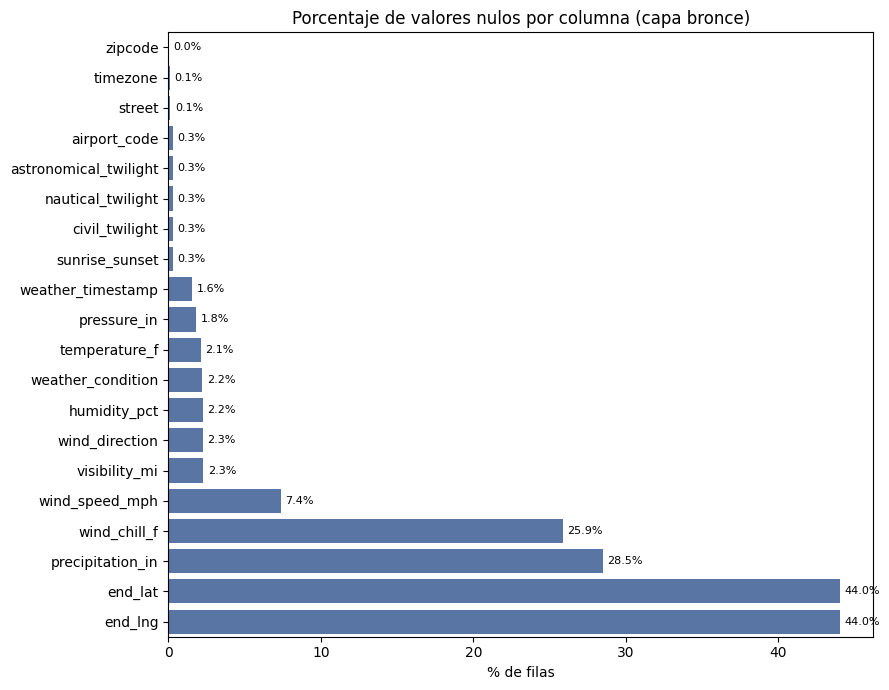

In [ ]:
# Porcentaje de nulos por columna (solo columnas con nulos)
plot_df = tabla_calidad[tabla_calidad['nulos_pct'] > 0].sort_values('nulos_pct')
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
sns.barplot(data=plot_df, x='nulos_pct', y='columna', color='#4C72B0', ax=ax)
for i, v in enumerate(plot_df['nulos_pct']):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=8)
ax.set_title('Porcentaje de valores nulos por columna (capa bronce)')
ax.set_xlabel('% de filas'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig(f'{DOCS}/nulos_por_columna.png', dpi=150)
plt.show()

### 3.1 Duración del evento (inicio vs. fin)

Se calcula `duración = end_time − start_time` en minutos para detectar duraciones negativas, nulas o excesivas.

In [ ]:
dur = (df.select(((F.unix_timestamp(convertir('end_time')) - F.unix_timestamp(convertir('start_time'))) / 60)
                 .alias('duracion_min')))
dur_res = dur.agg(
    F.count('duracion_min').alias('con_duracion'),
    F.sum(F.when(F.col('duracion_min') < 0, 1).otherwise(0)).alias('negativas'),
    F.sum(F.when(F.col('duracion_min') == 0, 1).otherwise(0)).alias('cero'),
    F.sum(F.when(F.col('duracion_min') > 24 * 60, 1).otherwise(0)).alias('mayor_24h'),
    F.sum(F.when(F.col('duracion_min') > 7 * 24 * 60, 1).otherwise(0)).alias('mayor_7_dias'),
    F.expr('percentile_approx(duracion_min, 0.5)').alias('mediana_min'),
    F.max('duracion_min').alias('max_min'),
)
dur_res.show()

# Formatos de fecha inconsistentes: longitud del texto de start_time
df.groupBy(F.length('start_time').alias('largo_start_time')).count().orderBy('largo_start_time').show()

+------------+---------+----+---------+------------+-----------------+---------+
|con_duracion|negativas|cero|mayor_24h|mayor_7_dias|      mediana_min|  max_min|
+------------+---------+----+---------+------------+-----------------+---------+
|     7728394|        0|   0|    34981|        6824|74.83333333333333|2812939.0|
+------------+---------+----+---------+------------+-----------------+---------+

+----------------+-------+
|largo_start_time|  count|
+----------------+-------+
|              19|6985228|
|              26|  60844|
|              29| 682322|
+----------------+-------+



### 3.2 Duplicados

In [ ]:
# (a) Duplicados por identificador
ids_distintos = df.select('id').distinct().count()
print(f'Filas: {N_FILAS:,} | IDs distintos: {ids_distintos:,} | IDs repetidos: {N_FILAS - ids_distintos:,}')

# (b) Mismo evento con distinto ID: igual hora de inicio, coordenadas y severidad
grupos_dup = (df.groupBy('start_time', 'start_lat', 'start_lng', 'severity')
                .count()
                .filter(F.col('count') > 1))
dup = grupos_dup.agg(F.count('*').alias('grupos_repetidos'),
                     F.sum(F.col('count') - 1).alias('filas_sobrantes')).collect()[0]
print(f"Eventos repetidos: {dup['grupos_repetidos']:,} grupos | filas que sobran: {dup['filas_sobrantes']:,}")

Filas: 7,728,394 | IDs distintos: 7,728,394 | IDs repetidos: 0
Eventos repetidos: 298,258 grupos | filas que sobran: 374,273


In [ ]:
# Comprobación puntual con filter(): ver un grupo duplicado completo
ejemplo = grupos_dup.orderBy(F.desc('count')).first()
if ejemplo:
    (df.filter((F.col('start_time') == ejemplo['start_time']) &
               (F.col('start_lat') == ejemplo['start_lat']) &
               (F.col('start_lng') == ejemplo['start_lng']) &
               (F.col('severity') == ejemplo['severity']))
       .select('id', 'source', 'severity', 'start_time', 'start_lat', 'start_lng', 'street', 'city', 'state')
       .show(truncate=False))

+---------+-------+--------+-------------------+---------+-----------+------+---------+-----+
|id       |source |severity|start_time         |start_lat|start_lng  |street|city     |state|
+---------+-------+--------+-------------------+---------+-----------+------+---------+-----+
|A-6620239|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6621833|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6642163|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6650693|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6657275|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6665158|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6681058|Source1|2       |2020-11-10 13:09:30|41.950875|-122.590137|I-5 S |Hornbrook|CA   |
|A-6684433|Source1|2       |2020-11-10 13:09:30|41.950875|-1

### 3.3 Categorías inconsistentes y sesgos de recolección

In [ ]:
# Dirección del viento: mismas categorías escritas de varias formas (CALM/Calm, VAR/Variable, North/N...)
print('Valores distintos de wind_direction:', df.select('wind_direction').distinct().count())
df.groupBy('wind_direction').count().orderBy(F.desc('count')).show(30)

Valores distintos de wind_direction: 25
+--------------+------+
|wind_direction| count|
+--------------+------+
|          CALM|961624|
|             S|419989|
|           SSW|384840|
|             W|383913|
|           WNW|378781|
|            NW|369352|
|          Calm|368557|
|            SW|364470|
|           WSW|353806|
|           SSE|349110|
|           NNW|333427|
|             N|307151|
|            SE|294901|
|             E|278914|
|           ESE|268311|
|            NE|258639|
|           ENE|258474|
|           NNE|255311|
|           VAR|250566|
|         South|177375|
|          NULL|175206|
|          West|164751|
|         North|153385|
|      Variable|113996|
|          East|103545|
+--------------+------+



In [ ]:
# Condición climática: más de 100 categorías; se agruparán en ~8 grupos en la capa plata
print('Valores distintos de weather_condition:', df.select('weather_condition').distinct().count())
df.groupBy('weather_condition').count().orderBy(F.desc('count')).show(30, truncate=False)

Valores distintos de weather_condition: 145
+-----------------------+-------+
|weather_condition      |count  |
+-----------------------+-------+
|Fair                   |2560802|
|Mostly Cloudy          |1016195|
|Cloudy                 |817082 |
|Clear                  |808743 |
|Partly Cloudy          |698972 |
|Overcast               |382866 |
|Light Rain             |352957 |
|Scattered Clouds       |204829 |
|NULL                   |173459 |
|Light Snow             |128680 |
|Fog                    |99238  |
|Rain                   |84331  |
|Haze                   |76223  |
|Fair / Windy           |35671  |
|Heavy Rain             |32309  |
|Light Drizzle          |22684  |
|Thunder in the Vicinity|17611  |
|Cloudy / Windy         |17035  |
|T-Storm                |16810  |
|Mostly Cloudy / Windy  |16508  |
|Snow                   |15537  |
|Thunder                |14202  |
|Light Rain with Thunder|13597  |
|Smoke                  |12668  |
|Wintry Mix             |11703  |
|Par

In [ ]:
# Formato del código postal: 5 dígitos vs ZIP+4 vs otros
(df.withColumn('formato_zip',
        F.when(F.col('zipcode').rlike(r'^\d{5}$'), '5 dígitos')
         .when(F.col('zipcode').rlike(r'^\d{5}-\d{4}$'), 'ZIP+4')
         .when(es_nulo('zipcode'), 'nulo')
         .otherwise('otro'))
   .groupBy('formato_zip').count().orderBy(F.desc('count')).show())

# Columnas con un solo valor (no aportan información)
print('Valores de country:', [r['country'] for r in df.select('country').distinct().collect()])
print('Valores de turning_loop:', [r['turning_loop'] for r in df.select('turning_loop').distinct().collect()])

+-----------+-------+
|formato_zip|  count|
+-----------+-------+
|  5 dígitos|5458211|
|      ZIP+4|2265251|
|       otro|   3017|
|       nulo|   1915|
+-----------+-------+

Valores de country: ['US']
Valores de turning_loop: ['False']


In [ ]:
# Distribución de severidad y de la fuente por año: evidencia del sesgo de recolección
anio = F.substring('start_time', 1, 4).alias('anio')
sev_anio = (df.groupBy(anio).pivot('severity', ['1', '2', '3', '4']).count()
              .orderBy('anio').toPandas().set_index('anio').fillna(0).astype(int))
sev_anio['total'] = sev_anio.sum(axis=1)
display(sev_anio)

fuente_anio = (df.groupBy(anio).pivot('source').count()
                 .orderBy('anio').toPandas().set_index('anio').fillna(0).astype(int))
display(fuente_anio)

,1,2,3,4,total
anio,,,,,
2016,225,270026,126215,14355,410821
2017,282,462474,231169,24168,718093
2018,259,574668,292706,25793,893426
2019,203,688144,237853,28103,954303
2020,28371,934123,185352,31067,1178913
2021,151,1384628,148085,30889,1563753
2022,37875,1603346,77957,43274,1762452
2023,0,239572,0,7061,246633


,Source1,Source2,Source3
anio,,,
2016,129560,279666,1595
2017,170702,539528,7863
2018,167761,714373,11292
2019,262369,672608,19326
2020,708669,448305,21939
2021,1113668,431482,18603
2022,1526270,219411,16771
2023,246633,0,0


In [ ]:
# Verificación: la suma por año debe coincidir con el total de filas
print('Suma por año:', f"{int(sev_anio['total'].sum()):,}", '| count():', f'{N_FILAS:,}',
      '| ¿coinciden?', int(sev_anio['total'].sum()) == N_FILAS)

Suma por año: 7,728,394 | count(): 7,728,394 | ¿coinciden? True


## 4. Resumen del diagnóstico

- **Volumen:** 7.728.394 filas y 46 columnas; CSV de 2.916,5 MB (zip de 653,1 MB) y Parquet de 763,8 MB.
- **Nulos:** las columnas con más nulos son `end_lat`/`end_lng` (44,03 %), `precipitation_in` (28,51 %), `wind_chill_f` (25,87 %) y `wind_speed_mph` (7,39 %); el resto de variables de clima está entre 1,8 % y 2,3 %.
- **Tipos incorrectos:** todas las columnas llegan como texto y ningún valor falla al convertirse a su tipo esperado; sin embargo, 743.166 fechas de `start_time` no siguen el formato estándar (682.322 con nanosegundos y 60.844 con microsegundos).
- **Duplicados:** 0 IDs repetidos; 374.273 filas sobrantes (4,84 %) en 298.258 grupos que corresponden al mismo evento con distinto ID.
- **Atípicos:** el método IQR no es adecuado para `severity` (ordinal) ni `visibility_mi` (concentrada en 10); con límites físicos se detectan 10.047 visibilidades > 20 mi, 451 presiones fuera de 20–32 inHg, 86 distancias > 100 mi, 66 temperaturas, 60 precipitaciones, 51 velocidades de viento y 41 sensaciones térmicas fuera de rango. No hay duraciones negativas; 34.981 superan 24 horas y 6.824 superan 7 días (máximo ≈ 5,3 años).
- **Categorías inconsistentes:** `wind_direction` tiene 24 valores para 18 categorías reales (CALM/Calm, VAR/Variable, S/South, W/West, N/North, E/East); `weather_condition` tiene 144 categorías; 2.265.251 códigos postales (29,3 %) están en formato ZIP+4.
- **Columnas sin información:** `country` (solo "US") y `turning_loop` (solo "False").
- **Sesgo de recolección:** Source2 predomina en 2016–2019 y Source1 desde 2020; la severidad 3 cae de 292.706 casos (2018) a 77.957 (2022) y a 0 en 2023, y 2023 solo cubre enero a marzo (246.633 filas). Las comparaciones de severidad entre años se tratarán como limitación.

**Siguiente paso:** parte 2, más abajo en este notebook.


# Parte 2 · Limpieza (capa plata), procesamiento con PySpark y capa oro inicial

In [ ]:
# Continuación: reutiliza la sesión de Spark y la capa bronce de la parte 1
def a_drive(local, destino):
    # Copia una carpeta del disco local de Colab a Drive, reemplazando la anterior
    if os.path.exists(destino):
        shutil.rmtree(destino)
    shutil.copytree(local, destino)

bronce_local = f'{TMP}/bronze_parquet'
if not os.path.exists(f'{bronce_local}/_SUCCESS'):
    shutil.copytree(BRONZE_PQ, bronce_local, dirs_exist_ok=True)
bronce = spark.read.parquet(bronce_local)
N_BRONCE = bronce.count()
print(f'Filas en bronce: {N_BRONCE:,}')

Filas en bronce: 7,728,394


## 5. Reglas de limpieza (bronce → plata)

Cada regla se basa en el diagnóstico de la parte 1:

| # | Problema detectado | Decisión | Justificación |
|---|---|---|---|
| 1 | Todo llega como texto; 743.166 fechas con fracciones de segundo | Tomar los primeros 19 caracteres y convertir a `timestamp`; castear números, severidad y booleanos | Las fracciones son ceros de relleno; unificar el formato permite operar con fechas |
| 2 | Filas sin datos críticos | Eliminar filas sin `start_time`, `state`, `severity` o coordenadas de inicio | Sin esos campos el registro no sirve para ninguna pregunta |
| 3 | 374.273 filas del mismo evento con distinto ID | Conservar una fila por (`start_time`, `start_lat`, `start_lng`, `severity`) | Contarlas varias veces infla los totales de accidentes |
| 4 | Valores físicamente imposibles | Convertirlos a nulo (no se borra la fila) | El error está en un sensor, no en el accidente; el resto de la fila sigue siendo válido |
| 5 | Duraciones de hasta ~5,3 años | `duration_min` > 7 días (10.080 min) → nulo | Un bloqueo vial de más de una semana es un error de cierre del evento |
| 6 | `wind_direction` con 24 variantes | Unificar a 18 categorías (16 rumbos + Calm + Variable) | Son la misma categoría escrita distinto |
| 7 | `weather_condition` con 144 categorías | Agrupar en 7 grupos (`weather_group`) y marcar viento en `is_windy`; se conserva el original | 144 categorías no se pueden comparar ni graficar |
| 8 | 29,3 % de códigos postales en formato ZIP+4 | Dejar los 5 primeros dígitos | Formato único para agrupar |
| 9 | Columnas sin aporte | Eliminar `country` y `turning_loop` (un solo valor), `end_lat`/`end_lng` (44 % nulos, no se usan), `wind_chill_f` (26 % nulos, redundante con temperatura), `nautical_twilight`/`astronomical_twilight` (redundantes) y `description` | Reducen tamaño sin perder información útil; `description` es texto libre que puede contener datos no necesarios (principio de minimización, Ley 1581 de 2012) |
| 10 | Unidades imperiales | Convertir a °C, km, km/h, mm y hPa | Público objetivo hispanohablante |
| 11 | `precipitation_in` con 28,5 % de nulos | Se deja el nulo como nulo | No se puede asumir que un nulo significa que no llovió |

In [ ]:
NUM_COLS  = ['start_lat', 'start_lng', 'distance_mi', 'temperature_f', 'humidity_pct',
             'pressure_in', 'visibility_mi', 'wind_speed_mph', 'precipitation_in']
TS_COLS   = ['start_time', 'end_time', 'weather_timestamp']
INFRA     = ['amenity', 'bump', 'crossing', 'give_way', 'junction', 'no_exit', 'railway',
             'roundabout', 'station', 'stop', 'traffic_calming', 'traffic_signal']
LIMITES = {
    'start_lat': (24, 50), 'start_lng': (-125, -66), 'distance_mi': (0, 100),
    'temperature_f': (-50, 130), 'humidity_pct': (0, 100), 'pressure_in': (20, 32),
    'visibility_mi': (0, 20), 'wind_speed_mph': (0, 150), 'precipitation_in': (0, 10),
}
MAX_DURACION_MIN = 7 * 24 * 60

def a_timestamp(c):
    return F.to_timestamp(F.substring(F.col(c), 1, 19), 'yyyy-MM-dd HH:mm:ss')

def texto_limpio(c):
    v = F.trim(F.col(c))
    return F.when((v == '') | F.lower(v).isin('nan', 'null', 'none', 'n/a'), None).otherwise(v)

def en_rango(c):
    lo, hi = LIMITES[c]
    return F.when((F.col(c) >= lo) & (F.col(c) <= hi), F.col(c))

def grupo_clima(c):
    w = F.lower(F.col(c))
    return (F.when(w.isNull(), None)
             .when(w.contains('n/a precipitation'), 'Otro')
             .when(w.rlike('thunder|t-storm|tornado|funnel|squall'), 'Tormenta')
             .when(w.rlike('snow|sleet|ice|wintry|freezing|hail'), 'Nieve/Hielo')
             .when(w.rlike('rain|drizzle|shower|precipitation'), 'Lluvia')
             .when(w.rlike('fog|haze|mist|smoke|dust|sand|ash'), 'Niebla/Humo/Polvo')
             .when(w.rlike('cloud|overcast'), 'Nublado')
             .when(w.rlike('fair|clear'), 'Despejado')
             .otherwise('Otro'))

def direccion_viento(c):
    v = F.upper(F.trim(F.col(c)))
    return (F.when(v.isNull() | (v == ''), None)
             .when(v == 'CALM', 'Calm')
             .when(v.isin('VAR', 'VARIABLE'), 'Variable')
             .when(v == 'NORTH', 'N').when(v == 'SOUTH', 'S')
             .when(v == 'EAST', 'E').when(v == 'WEST', 'W')
             .otherwise(v))

DIAS = {1: 'Lunes', 2: 'Martes', 3: 'Miércoles', 4: 'Jueves', 5: 'Viernes', 6: 'Sábado', 7: 'Domingo'}

In [ ]:
# Regla 1: tipos y formatos
df = bronce
for c in TS_COLS:
    df = df.withColumn(c, a_timestamp(c))
for c in NUM_COLS:
    df = df.withColumn(c, texto_limpio(c).cast('double'))
df = df.withColumn('severity', F.col('severity').cast('int'))
for c in INFRA:
    df = df.withColumn(c, F.col(c) == 'True')
for c in ['source', 'street', 'city', 'county', 'state', 'zipcode', 'timezone', 'airport_code',
          'weather_condition', 'sunrise_sunset', 'civil_twilight']:
    df = df.withColumn(c, texto_limpio(c))

# Regla 2: filas sin datos críticos
df = df.dropna(subset=['start_time', 'state', 'severity', 'start_lat', 'start_lng'])
N_CRITICOS = df.count()
print(f'Filas eliminadas por datos críticos faltantes: {N_BRONCE - N_CRITICOS:,}')

# Regla 3: duplicados del mismo evento
df = df.dropDuplicates(['start_time', 'start_lat', 'start_lng', 'severity'])
N_SIN_DUP = df.count()
print(f'Filas eliminadas por duplicado: {N_CRITICOS - N_SIN_DUP:,} | filas restantes: {N_SIN_DUP:,}')

Filas eliminadas por datos críticos faltantes: 0
Filas eliminadas por duplicado: 487,992 | filas restantes: 7,240,402


In [ ]:
# Reglas 4 a 11
for c in LIMITES:
    df = df.withColumn(c, en_rango(c))                                    # regla 4

duracion = (F.unix_timestamp('end_time') - F.unix_timestamp('start_time')) / 60
dow = ((F.dayofweek('start_time') + 5) % 7) + 1                          # 1 = lunes ... 7 = domingo
dias_map = F.create_map(*[F.lit(x) for kv in DIAS.items() for x in kv])

plata = (df
    .withColumn('duration_min', F.when((duracion >= 0) & (duracion <= MAX_DURACION_MIN),
                                       F.round(duracion, 1)))             # regla 5
    .withColumn('wind_direction', direccion_viento('wind_direction'))    # regla 6
    .withColumn('weather_group', grupo_clima('weather_condition'))       # regla 7
    .withColumn('is_windy', F.lower('weather_condition').contains('wind'))
    .withColumn('zipcode', F.when(F.substring('zipcode', 1, 5).rlike(r'^\d{5}$'),
                                  F.substring('zipcode', 1, 5)))          # regla 8
    # Regla 10: unidades métricas
    .withColumn('distance_km',      F.round(F.col('distance_mi') * 1.609344, 3))
    .withColumn('temperature_c',    F.round((F.col('temperature_f') - 32) * 5 / 9, 1))
    .withColumn('pressure_hpa',     F.round(F.col('pressure_in') * 33.8639, 1))
    .withColumn('visibility_km',    F.round(F.col('visibility_mi') * 1.609344, 2))
    .withColumn('wind_speed_kmh',   F.round(F.col('wind_speed_mph') * 1.609344, 1))
    .withColumn('precipitation_mm', F.round(F.col('precipitation_in') * 25.4, 2))
    # Variables derivadas para el análisis
    .withColumn('is_severe', F.col('severity') >= 3)
    .withColumn('year', F.year('start_time'))
    .withColumn('month', F.month('start_time'))
    .withColumn('hour', F.hour('start_time'))
    .withColumn('day_of_week', dow)
    .withColumn('day_name', dias_map[dow])
    .withColumn('is_partial_year', F.col('year') == 2023)
    # Regla 9: columnas eliminadas (se omiten del select)
    .select('id', 'source', 'severity', 'is_severe', 'start_time', 'end_time', 'duration_min',
            'year', 'month', 'day_of_week', 'day_name', 'hour', 'is_partial_year',
            'start_lat', 'start_lng', 'distance_km', 'street', 'city', 'county', 'state',
            'zipcode', 'timezone', 'airport_code', 'weather_timestamp', 'temperature_c',
            'humidity_pct', 'pressure_hpa', 'visibility_km', 'wind_direction',
            'wind_speed_kmh', 'precipitation_mm', 'weather_condition', 'weather_group',
            'is_windy', *INFRA, 'sunrise_sunset', 'civil_twilight'))

plata.printSchema()

root
 |-- id: string (nullable = true)
 |-- source: string (nullable = true)
 |-- severity: integer (nullable = true)
 |-- is_severe: boolean (nullable = true)
 |-- start_time: timestamp (nullable = true)
 |-- end_time: timestamp (nullable = true)
 |-- duration_min: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- day_name: string (nullable = true)
 |-- hour: integer (nullable = true)
 |-- is_partial_year: boolean (nullable = true)
 |-- start_lat: double (nullable = true)
 |-- start_lng: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- street: string (nullable = true)
 |-- city: string (nullable = true)
 |-- county: string (nullable = true)
 |-- state: string (nullable = true)
 |-- zipcode: string (nullable = true)
 |-- timezone: string (nullable = true)
 |-- airport_code: string (nullable = true)
 |-- weather_timestamp: timestamp (nullable = true)
 |-- temperatur

In [ ]:
# Escribir plata particionada por año: primero en disco local y luego copia a Drive
plata_local = f'{TMP}/silver_parquet'
(plata.repartition('year')
      .write.mode('overwrite')
      .partitionBy('year')
      .parquet(plata_local))
a_drive(plata_local, f'{SILVER}/accidentes')

plata = spark.read.parquet(plata_local)
N_PLATA = plata.count()
print(f'Filas en plata: {N_PLATA:,} | columnas: {len(plata.columns)} | tamaño: {tam_mb(plata_local):.1f} MB')
print(f'Filas eliminadas en total: {N_BRONCE - N_PLATA:,} ({100 * (N_BRONCE - N_PLATA) / N_BRONCE:.2f} %)')

Filas en plata: 7,240,402 | columnas: 48 | tamaño: 450.6 MB
Filas eliminadas en total: 487,992 (6.31 %)


## 6. Métricas de calidad antes y después

Todas las cifras se calculan aquí sobre bronce (antes) y plata (después), con los mismos criterios.

In [ ]:
# Métricas sobre bronce (antes)
b = bronce.select(
    *[F.when(~(F.col(c).isNull() | (F.trim(F.col(c)) == '') |
               F.lower(F.trim(F.col(c))).isin('nan', 'null', 'none', 'n/a')),
             F.col(c).cast('double')).alias(c) for c in LIMITES],
    a_timestamp('start_time').alias('st'), a_timestamp('end_time').alias('et'),
    F.length('start_time').alias('largo_st'), 'zipcode', 'wind_direction', 'weather_condition')

antes = b.agg(
    F.sum(sum(F.when((F.col(c) < lo) | (F.col(c) > hi), 1).otherwise(0)
              for c, (lo, hi) in LIMITES.items())).alias('fuera_limite'),
    F.sum(F.when(F.col('largo_st') != 19, 1).otherwise(0)).alias('fechas_no_estandar'),
    F.sum(F.when((F.unix_timestamp('et') - F.unix_timestamp('st')) / 60 > MAX_DURACION_MIN, 1)
           .otherwise(0)).alias('duracion_mayor_7d'),
    F.sum(F.when(F.col('zipcode').isNotNull() & ~F.col('zipcode').rlike(r'^\d{5}$'), 1)
           .otherwise(0)).alias('zip_no_estandar'),
    F.countDistinct('wind_direction').alias('cat_viento'),
    F.countDistinct('weather_condition').alias('cat_clima'),
).collect()[0].asDict()

dup_antes = (bronce.select(a_timestamp('start_time').alias('st'), 'start_lat', 'start_lng', 'severity')
                   .groupBy('st', 'start_lat', 'start_lng', 'severity').count()
                   .filter('count > 1').agg(F.sum(F.col('count') - 1)).collect()[0][0])

# Métricas sobre plata (después)
LIM_PLATA = {'start_lat': (24, 50), 'start_lng': (-125, -66), 'distance_km': (0, 160.94),
             'temperature_c': (-45.6, 54.5), 'humidity_pct': (0, 100), 'pressure_hpa': (677.2, 1083.7),
             'visibility_km': (0, 32.19), 'wind_speed_kmh': (0, 241.4), 'precipitation_mm': (0, 254)}
despues = plata.agg(
    F.sum(sum(F.when((F.col(c) < lo) | (F.col(c) > hi), 1).otherwise(0)
              for c, (lo, hi) in LIM_PLATA.items())).alias('fuera_limite'),
    F.sum(F.when(F.col('duration_min') > MAX_DURACION_MIN, 1).otherwise(0)).alias('duracion_mayor_7d'),
    F.sum(F.when(F.col('zipcode').isNotNull() & ~F.col('zipcode').rlike(r'^\d{5}$'), 1)
           .otherwise(0)).alias('zip_no_estandar'),
    F.countDistinct('wind_direction').alias('cat_viento'),
    F.countDistinct('weather_group').alias('cat_clima'),
).collect()[0].asDict()

dup_despues = (plata.groupBy('start_time', 'start_lat', 'start_lng', 'severity').count()
                    .filter('count > 1').count())

tipos_texto_antes   = sum(1 for f in bronce.schema.fields if isinstance(f.dataType, T.StringType))
tipos_texto_despues = sum(1 for f in plata.schema.fields if isinstance(f.dataType, T.StringType))

metricas = pd.DataFrame([
    ['Filas', N_BRONCE, N_PLATA],
    ['Columnas', len(bronce.columns), len(plata.columns)],
    ['Columnas de tipo texto', tipos_texto_antes, tipos_texto_despues],
    ['Fechas con formato no estándar', antes['fechas_no_estandar'], 0],
    ['Filas duplicadas (mismo evento)', dup_antes, dup_despues],
    ['Valores fuera de límite físico', antes['fuera_limite'], despues['fuera_limite']],
    ['Duraciones mayores a 7 días', antes['duracion_mayor_7d'], despues['duracion_mayor_7d']],
    ['Códigos postales no estándar', antes['zip_no_estandar'], despues['zip_no_estandar']],
    ['Categorías de dirección del viento', antes['cat_viento'], despues['cat_viento']],
    ['Categorías de condición climática', antes['cat_clima'], despues['cat_clima']],
], columns=['metrica', 'antes', 'despues'])
metricas.to_csv(f'{DOCS}/metricas_antes_despues.csv', index=False)
metricas

,metrica,antes,despues
0,Filas,7728394,7240402
1,Columnas,46,48
2,Columnas de tipo texto,46,15
3,Fechas con formato no estándar,743166,0
4,Filas duplicadas (mismo evento),487992,0
5,Valores fuera de límite físico,10761,0
6,Duraciones mayores a 7 días,6824,0
7,Códigos postales no estándar,2268268,0
8,Categorías de dirección del viento,24,18
9,Categorías de condición climática,144,7


In [ ]:
# Nulos por columna en plata (aumentan en algunas columnas porque los valores imposibles se convirtieron a nulo)
nulos = plata.agg(*[F.sum(F.col(c).isNull().cast('int')).alias(c) for c in plata.columns]).toPandas().T
nulos.columns = ['nulos']
nulos['nulos_pct'] = (100 * nulos['nulos'] / N_PLATA).round(2)
nulos = nulos.rename_axis('columna').reset_index()
nulos.to_csv(f'{DOCS}/calidad_despues.csv', index=False)
nulos[nulos['nulos'] > 0].sort_values('nulos_pct', ascending=False)

,columna,nulos,nulos_pct
29,precipitation_mm,2174193,30.03
28,wind_speed_kmh,555477,7.67
26,visibility_km,174558,2.41
24,humidity_pct,161651,2.23
30,weather_condition,161636,2.23
27,wind_direction,161106,2.23
32,is_windy,161636,2.23
31,weather_group,161636,2.23
23,temperature_c,152190,2.10
25,pressure_hpa,130960,1.81


In [ ]:
# Comprobaciones puntuales con filter()
print('Categorías finales de wind_direction:')
plata.groupBy('wind_direction').count().orderBy(F.desc('count')).show(20)

print('Grupos de clima:')
plata.groupBy('weather_group').count().orderBy(F.desc('count')).show()

print('Ejemplo de cómo se agruparon algunas condiciones originales:')
(plata.filter(F.col('weather_condition').isin('Light Rain with Thunder', 'Wintry Mix', 'Haze', 'Fair / Windy'))
      .groupBy('weather_condition', 'weather_group', 'is_windy').count().show(truncate=False))

print('El evento duplicado de Hornbrook (CA) quedó una sola vez:')
(plata.filter((F.col('city') == 'Hornbrook') & (F.col('start_time') == '2020-11-10 13:09:30'))
      .select('id', 'start_time', 'street', 'city', 'state', 'severity').show())

Categorías finales de wind_direction:
+--------------+-------+
|wind_direction|  count|
+--------------+-------+
|          Calm|1249257|
|             S| 563089|
|             W| 514210|
|             N| 434111|
|           SSW| 362776|
|           WNW| 353629|
|             E| 353434|
|            NW| 344761|
|            SW| 343881|
|      Variable| 343132|
|           WSW| 332832|
|           SSE| 327687|
|           NNW| 311317|
|            SE| 274520|
|           ESE| 247914|
|            NE| 242547|
|           NNE| 240372|
|           ENE| 239827|
|          NULL| 161106|
+--------------+-------+

Grupos de clima:
+-----------------+-------+
|    weather_group|  count|
+-----------------+-------+
|        Despejado|3170770|
|          Nublado|2985991|
|           Lluvia| 482856|
|Niebla/Humo/Polvo| 188454|
|      Nieve/Hielo| 165456|
|             NULL| 161636|
|         Tormenta|  82383|
|             Otro|   2856|
+-----------------+-------+

Ejemplo de cómo se agruparon alg

## 7. Diccionario de datos de la capa plata (Electiva B)

**Responsables por fuente y capa:**

| Fuente / capa | Responsable |
|---|---|
| Fuente US Accidents (Kaggle) e ingesta a bronce | Juan Esteban Tovar |
| Capa plata (limpieza y diccionario) | Diego Esteban Buitrago |
| Capa oro y dashboard | Camilo Hernández |

*(Ajustar según el reparto real del equipo.)*

In [ ]:
DESCRIPCIONES = {
    'id': ('Identificador único del accidente', 'Sin cambios'),
    'source': ('Proveedor de API que reportó el accidente', 'Sin cambios'),
    'severity': ('Severidad del impacto en el tráfico (1 = bajo, 4 = alto)', 'Cast a entero'),
    'is_severe': ('Accidente grave (severidad 3 o 4)', 'Derivada de severity'),
    'start_time': ('Inicio del accidente (hora local)', 'Primeros 19 caracteres → timestamp'),
    'end_time': ('Fin del impacto en el tráfico (hora local)', 'Primeros 19 caracteres → timestamp'),
    'duration_min': ('Duración del impacto en minutos', 'end_time − start_time; > 7 días → nulo'),
    'year': ('Año del accidente (partición)', 'Derivada de start_time'),
    'month': ('Mes del accidente', 'Derivada de start_time'),
    'day_of_week': ('Día de la semana (1 = lunes … 7 = domingo)', 'Derivada de start_time'),
    'day_name': ('Nombre del día en español', 'Derivada de day_of_week'),
    'hour': ('Hora del día (0–23)', 'Derivada de start_time'),
    'is_partial_year': ('Año con datos incompletos (2023: enero–marzo)', 'Derivada de year'),
    'start_lat': ('Latitud del inicio del accidente', 'Cast a double; fuera de 24–50 → nulo'),
    'start_lng': ('Longitud del inicio del accidente', 'Cast a double; fuera de −125 a −66 → nulo'),
    'distance_km': ('Longitud de vía afectada (km)', 'mi × 1,609; > 100 mi → nulo'),
    'street': ('Calle', 'Trim'), 'city': ('Ciudad', 'Trim'), 'county': ('Condado', 'Trim'),
    'state': ('Código del estado (2 letras)', 'Trim'),
    'zipcode': ('Código postal de 5 dígitos', 'ZIP+4 → 5 primeros dígitos'),
    'timezone': ('Zona horaria', 'Trim'),
    'airport_code': ('Estación meteorológica (aeropuerto) más cercana', 'Trim'),
    'weather_timestamp': ('Hora de la observación del clima', 'Primeros 19 caracteres → timestamp'),
    'temperature_c': ('Temperatura (°C)', '(°F − 32) × 5/9; fuera de −50 a 130 °F → nulo'),
    'humidity_pct': ('Humedad relativa (%)', 'Cast a double; fuera de 0–100 → nulo'),
    'pressure_hpa': ('Presión atmosférica (hPa)', 'inHg × 33,86; fuera de 20–32 inHg → nulo'),
    'visibility_km': ('Visibilidad (km)', 'mi × 1,609; > 20 mi → nulo'),
    'wind_direction': ('Dirección del viento (16 rumbos, Calm, Variable)', 'Unificación de variantes'),
    'wind_speed_kmh': ('Velocidad del viento (km/h)', 'mph × 1,609; > 150 mph → nulo'),
    'precipitation_mm': ('Precipitación (mm)', 'in × 25,4; > 10 in → nulo; nulos se conservan'),
    'weather_condition': ('Condición climática original', 'Trim'),
    'weather_group': ('Grupo de condición climática (7 grupos)', 'Reglas por palabras clave'),
    'is_windy': ('La condición climática menciona viento', 'Derivada de weather_condition'),
    'sunrise_sunset': ('Día o noche según la posición del sol', 'Sin cambios'),
    'civil_twilight': ('Día o noche según el crepúsculo civil', 'Sin cambios'),
}
NOMBRES_INFRA = {'amenity': 'servicio público (amenity)', 'bump': 'reductor de velocidad',
                 'crossing': 'cruce peatonal', 'give_way': 'señal de ceda el paso',
                 'junction': 'intersección o salida', 'no_exit': 'vía sin salida',
                 'railway': 'paso férreo', 'roundabout': 'glorieta', 'station': 'estación',
                 'stop': 'señal de pare', 'traffic_calming': 'elemento de pacificación del tráfico',
                 'traffic_signal': 'semáforo'}
for c, n in NOMBRES_INFRA.items():
    DESCRIPCIONES[c] = (f'Hay {n} cerca del accidente', '"True"/"False" → booleano')

ejemplo = plata.filter(F.col('duration_min').isNotNull() & F.col('temperature_c').isNotNull()).first().asDict()
diccionario = pd.DataFrame([{
    'columna': f.name,
    'tipo': f.dataType.simpleString(),
    'descripcion': DESCRIPCIONES.get(f.name, ('', ''))[0],
    'ejemplo': str(ejemplo[f.name])[:30],
    'regla_transformacion': DESCRIPCIONES.get(f.name, ('', ''))[1],
} for f in plata.schema.fields])
diccionario.to_csv(f'{DOCS}/diccionario_plata.csv', index=False)
diccionario

,columna,tipo,descripcion,ejemplo,regla_transformacion
0,id,string,Identificador único del accidente,A-757745,Sin cambios
1,source,string,Proveedor de API que reportó el accidente,Source2,Sin cambios
2,severity,int,"Severidad del impacto en el tráfico (1 = bajo,...",3,Cast a entero
3,is_severe,boolean,Accidente grave (severidad 3 o 4),True,Derivada de severity
4,start_time,timestamp,Inicio del accidente (hora local),2022-01-01 00:06:13,Primeros 19 caracteres → timestamp
5,end_time,timestamp,Fin del impacto en el tráfico (hora local),2022-01-01 00:35:53,Primeros 19 caracteres → timestamp
6,duration_min,double,Duración del impacto en minutos,29.7,end_time − start_time; > 7 días → nulo
7,month,int,Mes del accidente,1,Derivada de start_time
8,day_of_week,int,Día de la semana (1 = lunes … 7 = domingo),6,Derivada de start_time
9,day_name,string,Nombre del día en español,Sábado,Derivada de day_of_week


## 8. Procesamiento con PySpark y capa oro inicial

### 8.1 Tabla de referencia de estados (para el join)

In [ ]:
REGIONES = {
    'Noreste': 'CT ME MA NH RI VT NJ NY PA',
    'Medio Oeste': 'IL IN MI OH WI IA KS MN MO NE ND SD',
    'Sur': 'DE FL GA MD NC SC VA DC WV AL KY MS TN AR LA OK TX',
    'Oeste': 'AZ CO ID MT NV NM UT WY AK CA HI OR WA',
}
NOMBRES = {'AL':'Alabama','AK':'Alaska','AZ':'Arizona','AR':'Arkansas','CA':'California','CO':'Colorado',
 'CT':'Connecticut','DE':'Delaware','DC':'District of Columbia','FL':'Florida','GA':'Georgia','HI':'Hawaii',
 'ID':'Idaho','IL':'Illinois','IN':'Indiana','IA':'Iowa','KS':'Kansas','KY':'Kentucky','LA':'Louisiana',
 'ME':'Maine','MD':'Maryland','MA':'Massachusetts','MI':'Michigan','MN':'Minnesota','MS':'Mississippi',
 'MO':'Missouri','MT':'Montana','NE':'Nebraska','NV':'Nevada','NH':'New Hampshire','NJ':'New Jersey',
 'NM':'New Mexico','NY':'New York','NC':'North Carolina','ND':'North Dakota','OH':'Ohio','OK':'Oklahoma',
 'OR':'Oregon','PA':'Pennsylvania','RI':'Rhode Island','SC':'South Carolina','SD':'South Dakota',
 'TN':'Tennessee','TX':'Texas','UT':'Utah','VT':'Vermont','VA':'Virginia','WA':'Washington',
 'WV':'West Virginia','WI':'Wisconsin','WY':'Wyoming'}
estados_pd = pd.DataFrame([(s, NOMBRES[s], reg) for reg, ss in REGIONES.items() for s in ss.split()],
                          columns=['state', 'state_name', 'region'])
estados_pd.to_csv(f'{REFERENCE}/states.csv', index=False)
estados = spark.read.option('header', True).csv(f'{REFERENCE}/states.csv')

print('Estados distintos en plata (conteo exacto):', plata.select('state').distinct().count())
sin_region = plata.join(estados, 'state', 'left_anti')
print('Filas cuyo estado no está en la tabla de referencia:', sin_region.count())

Estados distintos en plata (conteo exacto): 49
Filas cuyo estado no está en la tabla de referencia: 0


### 8.2 Accidentes por año (filtro + `groupBy`)

In [ ]:
por_anio = (plata.groupBy('year')
                 .agg(F.count('*').alias('accidentes'),
                      F.round(100 * F.avg(F.col('is_severe').cast('int')), 2).alias('pct_severos'))
                 .orderBy('year'))
por_anio.show()
total = por_anio.agg(F.sum('accidentes')).collect()[0][0]
print(f'Verificación: suma por año = {total:,} | count() de plata = {N_PLATA:,} | ¿coinciden? {total == N_PLATA}')

+----+----------+-----------+
|year|accidentes|pct_severos|
+----+----------+-----------+
|2016|    409290|      34.21|
|2017|    714272|      35.59|
|2018|    889101|      35.66|
|2019|    949412|      27.86|
|2020|   1058737|      19.66|
|2021|   1425302|      12.47|
|2022|   1568374|       7.63|
|2023|    225914|       3.05|
+----+----------+-----------+

Verificación: suma por año = 7,240,402 | count() de plata = 7,240,402 | ¿coinciden? True


### 8.3 Top 10 estados y accidentes por región (join), 2016–2022

In [ ]:
plata_2022 = plata.filter(F.col('year') <= 2022)
N_2022 = plata_2022.count()
print(f'Filas 2016–2022: {N_2022:,}')

top_estados = (plata_2022.join(estados, 'state')
                .groupBy('state', 'state_name', 'region')
                .agg(F.count('*').alias('accidentes'),
                     F.round(100 * F.avg(F.col('is_severe').cast('int')), 2).alias('pct_severos'))
                .withColumn('pct_del_total', F.round(100 * F.col('accidentes') / N_2022, 2))
                .orderBy(F.desc('accidentes')))
top_estados.show(10)

por_region = (plata_2022.join(estados, 'state')
                .groupBy('region')
                .agg(F.count('*').alias('accidentes'),
                     F.round(100 * F.avg(F.col('is_severe').cast('int')), 2).alias('pct_severos'))
                .withColumn('pct_del_total', F.round(100 * F.col('accidentes') / N_2022, 2))
                .orderBy(F.desc('accidentes')))
por_region.show()
print('Verificación región:', por_region.agg(F.sum('accidentes')).collect()[0][0] == N_2022)

Filas 2016–2022: 7,014,488
+-----+--------------+-----------+----------+-----------+-------------+
|state|    state_name|     region|accidentes|pct_severos|pct_del_total|
+-----+--------------+-----------+----------+-----------+-------------+
|   CA|    California|      Oeste|   1562207|      18.18|        22.27|
|   FL|       Florida|        Sur|    761829|      15.19|        10.86|
|   TX|         Texas|        Sur|    550817|      23.04|         7.85|
|   SC|South Carolina|        Sur|    364499|      12.39|          5.2|
|   NY|      New York|    Noreste|    307884|      25.57|         4.39|
|   NC|North Carolina|        Sur|    307569|      12.53|         4.38|
|   VA|      Virginia|        Sur|    272773|      24.84|         3.89|
|   PA|  Pennsylvania|    Noreste|    259438|      17.26|          3.7|
|   MN|     Minnesota|Medio Oeste|    170801|      17.94|         2.43|
|   IL|      Illinois|Medio Oeste|    161020|      38.08|          2.3|
+-----+--------------+-----------+---

### 8.4 Accidentes y proporción de graves por hora del día (Spark SQL)

In [ ]:
plata.createOrReplaceTempView('accidentes')
por_hora = spark.sql('''
    SELECT hour,
           COUNT(*)                                        AS accidentes,
           SUM(CAST(is_severe AS INT))                     AS graves,
           ROUND(100 * AVG(CAST(is_severe AS INT)), 2)     AS pct_graves
    FROM accidentes
    WHERE year <= 2022
    GROUP BY hour
    ORDER BY hour
''')
por_hora.show(24)
print('Verificación:', por_hora.agg(F.sum('accidentes')).collect()[0][0] == N_2022)

+----+----------+------+----------+
|hour|accidentes|graves|pct_graves|
+----+----------+------+----------+
|   0|     96520| 17259|     17.88|
|   1|     82747| 13350|     16.13|
|   2|     79996| 14317|      17.9|
|   3|     72213| 14374|     19.91|
|   4|    147041| 33685|     22.91|
|   5|    208671| 45063|      21.6|
|   6|    376307| 80522|      21.4|
|   7|    549898|109159|     19.85|
|   8|    543223|108400|     19.95|
|   9|    337346| 74575|     22.11|
|  10|    317922| 68199|     21.45|
|  11|    326784| 68728|     21.03|
|  12|    318065| 68031|     21.39|
|  13|    352125| 73398|     20.84|
|  14|    398496| 80412|     20.18|
|  15|    469320| 96270|     20.51|
|  16|    524658|111358|     21.22|
|  17|    521851|113359|     21.72|
|  18|    392644| 90474|     23.04|
|  19|    268283| 62392|     23.26|
|  20|    202981| 47598|     23.45|
|  21|    170002| 38531|     22.67|
|  22|    148200| 33024|     22.28|
|  23|    109195| 18982|     17.38|
+----+----------+------+----

### 8.5 Proporción de accidentes graves por grupo de clima (2016–2022)

In [ ]:
por_clima = (plata_2022.filter(F.col('weather_group').isNotNull())
               .groupBy('weather_group')
               .agg(F.count('*').alias('accidentes'),
                    F.round(100 * F.avg(F.col('is_severe').cast('int')), 2).alias('pct_graves'))
               .orderBy(F.desc('pct_graves')))
por_clima.show()

+-----------------+----------+----------+
|    weather_group|accidentes|pct_graves|
+-----------------+----------+----------+
|           Lluvia|    460409|     25.21|
|      Nieve/Hielo|    149714|     23.35|
|          Nublado|   2903157|     23.28|
|         Tormenta|     81325|     22.63|
|        Despejado|   3079581|     18.41|
|Niebla/Humo/Polvo|    182084|     17.54|
|             Otro|      2572|     11.98|
+-----------------+----------+----------+



### 8.6 Capa oro inicial

Tablas pequeñas y agregadas que consume el dashboard. Cada una se verifica contra el total de plata.

In [ ]:
def guardar_oro(df, nombre, veces=1):
    # veces: cuántas veces aparece cada accidente en la tabla (12 en infraestructura, una por elemento)
    df.coalesce(1).write.mode('overwrite').parquet(f'{TMP}/gold/{nombre}')
    a_drive(f'{TMP}/gold/{nombre}', f'{GOLD}/{nombre}')
    pdf = pd.read_parquet(f'{TMP}/gold/{nombre}')
    print(f"{nombre}: {len(pdf):,} filas | {tam_mb(f'{TMP}/gold/{nombre}'):.2f} MB | "
          f"suma de accidentes = {int(pdf['accidentes'].sum()):,} | esperado = {veces * N_PLATA:,} | "
          f"¿coinciden? {int(pdf['accidentes'].sum()) == veces * N_PLATA}")
    return pdf

graves = F.sum(F.col('is_severe').cast('int')).alias('graves')

oro_anio_mes_estado = (plata.join(F.broadcast(estados), 'state', 'left')
    .groupBy('year', 'month', 'state', 'state_name', 'region')
    .agg(F.count('*').alias('accidentes'), graves,
         F.expr('percentile_approx(duration_min, 0.5)').alias('duracion_mediana_min')))

oro_hora_dia = (plata
    .groupBy('year', 'state', 'day_of_week', 'day_name', 'hour')
    .agg(F.count('*').alias('accidentes'), graves))

oro_clima = (plata
    .groupBy('year', 'state', 'weather_group', 'is_windy')
    .agg(F.count('*').alias('accidentes'), graves))

infra_expr = 'stack({n}, {pares}) as (elemento, presente)'.format(
    n=len(INFRA), pares=', '.join(f"'{c}', {c}" for c in INFRA))
oro_infra = (plata.select('year', 'is_severe', F.expr(infra_expr))
    .groupBy('year', 'elemento', 'presente')
    .agg(F.count('*').alias('accidentes'), F.sum(F.col('is_severe').cast('int')).alias('graves')))

g1 = guardar_oro(oro_anio_mes_estado, 'accidentes_anio_mes_estado')
g2 = guardar_oro(oro_hora_dia, 'accidentes_hora_dia')
g3 = guardar_oro(oro_clima, 'accidentes_clima')
g4 = guardar_oro(oro_infra, 'accidentes_infraestructura', veces=len(INFRA))
print(f'Tamaño total de la capa oro: {tam_mb(f"{TMP}/gold"):.2f} MB')

accidentes_anio_mes_estado: 3,957 filas | 0.04 MB | suma de accidentes = 7,240,402 | esperado = 7,240,402 | ¿coinciden? True
accidentes_hora_dia: 56,751 filas | 0.26 MB | suma de accidentes = 7,240,402 | esperado = 7,240,402 | ¿coinciden? True
accidentes_clima: 3,969 filas | 0.03 MB | suma de accidentes = 7,240,402 | esperado = 7,240,402 | ¿coinciden? True
accidentes_infraestructura: 192 filas | 0.00 MB | suma de accidentes = 86,884,824 | esperado = 86,884,824 | ¿coinciden? True
Tamaño total de la capa oro: 0.33 MB


In [ ]:
# Comprobación puntual: Florida 2021 en oro vs. filter() directo sobre plata
fl_oro   = int(g1[(g1['state'] == 'FL') & (g1['year'] == 2021)]['accidentes'].sum())
fl_plata = plata.filter((F.col('state') == 'FL') & (F.col('year') == 2021)).count()
print(f'FL 2021 → oro: {fl_oro:,} | plata: {fl_plata:,} | ¿coinciden? {fl_oro == fl_plata}')

FL 2021 → oro: 207,751 | plata: 207,751 | ¿coinciden? True


## 9. Resumen de la parte 2

> Completar con las cifras obtenidas arriba.

- **Limpieza:** de [N] filas en bronce quedan [N] en plata ([N] eliminadas, [N] %), con [N] columnas tipadas.
- **Calidad:** la tabla `docs/metricas_antes_despues.csv` resume el cambio en duplicados, fechas, valores fuera de límite, categorías y códigos postales.
- **Primeros resultados (2016–2022):** [año con más accidentes]; los 3 estados con más accidentes son [..]; la región con más accidentes es [..]; la hora con más accidentes es [..] y la de mayor proporción de graves es [..]; el grupo de clima con mayor proporción de graves es [..].
- **Capa oro:** 4 tablas, [N] MB en total, verificadas contra el total de plata.

**Archivos generados en Drive:** `data/silver/accidentes/`, `data/reference/states.csv`, `data/gold/*`, `docs/metricas_antes_despues.csv`, `docs/calidad_despues.csv`, `docs/diccionario_plata.csv`.

**Siguiente paso:** prototipo del dashboard en Streamlit (`app/app.py`) leyendo la capa oro.